
$\textcolor{purple}{\textbf{Cirrhosis}}$

Cirrhosis is illness presents the liver damage. This damage causes the disfunctionality of the function of the liver.
The damage can be caused by liver infenction, many years of alcohol usage and medication influence.

Blood tests for cirrhosis reflect changes in liver synthetic function, detoxification capacity, cell injury, and portal pressure.

Key Lab Values and Typical Changes in Cirrhosis

• Albumin: Low (<35–50 g/L or <3.5–5.0 g/dL)

    Meaning: The liver produces less albumin as scarring impairs its synthetic function, which can lead to fluid leaking into tissues (ascites or swelling).

• Prothrombin Time (PT) / INR: Prolonged / Elevated

    Meaning: The liver cannot make enough blood-clotting factors, increasing bleeding risks.

• Total / Direct Bilirubin: Elevated

    Meaning: The liver struggles to process and clear bilirubin (a breakdown product of red blood cells), which can cause jaundice (yellowing of the skin and eyes).

• Platelet Count: Low (Thrombocytopenia, often <150 × 10⁹/L)

    Meaning: Caused by a combination of reduced thrombopoietin production by the liver and platelet sequestration (trapping) in an enlarged spleen due to portal hypertension.

• AST and ALT (Aminotransferases): Variable / Mildly Elevated or Normal

    Meaning: These indicate ongoing liver cell injury. In advanced cirrhosis, levels can sometimes drop back toward normal. An AST:ALT ratio > 2:1 is classic for alcohol-related liver disease.

• Alkaline Phosphatase (ALP) & GGT: Normal to Elevated

    Meaning: Elevations can suggest concurrent bile duct stress or cholestasis (impaired bile flow).

• Creatinine & Sodium: Rising Creatinine / Low Sodium

    Meaning: Tracked closely because advanced liver disease can impact kidney function and fluid handling (risking hepatorenal syndrome).

Common Composite Scoring Systems

Clinicians combine these individual markers into clinical tools to stage severity, guide treatment, and prioritize care:

• FIB-4 Index: Uses age, AST, ALT, and platelet count to estimate liver fibrosis.

• MELD Score (Model for End-Stage Liver Disease): Uses bilirubin, INR, creatinine, and sodium to estimate short-term prognosis and organ severity.

• Child-Turcotte-Pugh (CTP) Score: Uses bilirubin, albumin, INR, ascites, and encephalopathy.

You can read more about liver monitoring panels via the Mayo Clinic Liver Function Tests Guide or clinical overviews like the American Academy of Family Physicians Cirrhosis Review.
Are you looking at specific lab results from a recent panel, or trying to understand monitoring for a known diagnosis? Sharing any specific numbers or symptoms helps me provide more relevant context.


In [107]:
%pip install pandas numpy scipy seaborn matplotlib 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


***Importing Libraries***

In [108]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

***Loading up the data***

In [109]:
cirrhosis = pd.read_csv('HepatitisCdata.csv')
cirrhosis

,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
610,611,3=Cirrhosis,62,f,32.0,416.6,5.9,110.3,50.0,5.57,6.30,55.7,650.9,68.5
611,612,3=Cirrhosis,64,f,24.0,102.8,2.9,44.4,20.0,1.54,3.02,63.0,35.9,71.3
612,613,3=Cirrhosis,64,f,29.0,87.3,3.5,99.0,48.0,1.66,3.63,66.7,64.2,82.0
613,614,3=Cirrhosis,46,f,33.0,NaN,39.0,62.0,20.0,3.56,4.20,52.0,50.0,71.0


In [110]:
cirrhosis_indian_file = pd.read_csv('indian_liver_patient.csv')
cirrhosis_indian_file 

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


Thses are two database sets. They show the main lab value examminating for setting a diagnosis  Cirrhosis.
In these two data sets: Hepatitis C and Indian Liver  Patient  I will show their relationship and the possibility to make the medical ratio based on these data.


In [111]:
pd.set_option('display.max_columns', None)
display(cirrhosis.head())
display(cirrhosis_indian_file.head())

,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [112]:
df1 = cirrhosis[['Category', 'Age', 'Sex', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'PROT']].copy()
df1['Source'] = 'Hepatitis_Dataset' 

df2 = cirrhosis_indian_file[['Dataset', 'Age', 'Gender', 'Albumin', 'Alkaline_Phosphotase', 
                             'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 
                             'Total_Bilirubin', 'Total_Protiens']].copy()


df1 = df1.rename(columns={
    'Category': 'Dataset',
    'Sex':  'Gender',
    'ALB': 'Albumin',
    'ALP': 'Alkaline_Phosphotase',
    'ALT': 'Alamine_Aminotransferase',
    'AST': 'Aspartate_Aminotransferase',
    'BIL': 'Total_Bilirubin',
    'PROT' : 'Total_Protiens'
})
df2['Source'] = 'Indian_Dataset'

In [113]:

df2['Gender'] = df2['Gender'].replace({'m': 'Male', 'f': 'Female'})

df2['Albumin'] = df2['Albumin'] * 10
df2['Total_Protiens'] = df2['Total_Protiens'] * 10 
df2['Total_Bilirubin'] = df2['Total_Bilirubin'] * 17.1 

df2['Dataset'] = df2['Dataset'].replace({1: 'Liver_Disease_General', 2: '0=Blood Donor'})
df2['Dataset'] = df2['Dataset'].replace({'0s=suspect Blood Donor': '0=Blood Donor'})

In [114]:
combined_datasets_cirrhosis = pd.concat([df1, df2], ignore_index=True)



In [115]:
display(combined_datasets_cirrhosis)

,Dataset,Age,Gender,Albumin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Bilirubin,Total_Protiens,Source
0,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.50,69.0,Hepatitis_Dataset
1,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.90,76.5,Hepatitis_Dataset
2,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.10,79.3,Hepatitis_Dataset
3,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.90,75.7,Hepatitis_Dataset
4,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.60,68.7,Hepatitis_Dataset
...,...,...,...,...,...,...,...,...,...,...
1193,0=Blood Donor,60,Male,16.0,500.0,20.0,34.0,8.55,59.0,Indian_Dataset
1194,Liver_Disease_General,40,Male,32.0,98.0,35.0,31.0,10.26,60.0,Indian_Dataset
1195,Liver_Disease_General,52,Male,32.0,245.0,48.0,49.0,13.68,64.0,Indian_Dataset
1196,Liver_Disease_General,31,Male,34.0,184.0,29.0,32.0,22.23,68.0,Indian_Dataset


In [116]:
print(combined_datasets_cirrhosis.info())

<class 'pandas.DataFrame'>
RangeIndex: 1198 entries, 0 to 1197
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Dataset                     1198 non-null   object 
 1   Age                         1198 non-null   int64  
 2   Gender                      1198 non-null   str    
 3   Albumin                     1197 non-null   float64
 4   Alkaline_Phosphotase        1180 non-null   float64
 5   Alamine_Aminotransferase    1197 non-null   float64
 6   Aspartate_Aminotransferase  1198 non-null   float64
 7   Total_Bilirubin             1198 non-null   float64
 8   Total_Protiens              1197 non-null   float64
 9   Source                      1198 non-null   str    
dtypes: float64(6), int64(1), object(1), str(2)
memory usage: 93.7+ KB
None


In [117]:
print("Missing Values from the Dataset", combined_datasets_cirrhosis.isnull())

Missing Values from the Dataset       Dataset    Age  Gender  Albumin  Alkaline_Phosphotase  \
0       False  False   False    False                 False   
1       False  False   False    False                 False   
2       False  False   False    False                 False   
3       False  False   False    False                 False   
4       False  False   False    False                 False   
...       ...    ...     ...      ...                   ...   
1193    False  False   False    False                 False   
1194    False  False   False    False                 False   
1195    False  False   False    False                 False   
1196    False  False   False    False                 False   
1197    False  False   False    False                 False   

      Alamine_Aminotransferase  Aspartate_Aminotransferase  Total_Bilirubin  \
0                        False                       False            False   
1                        False                       

Diagram:  about the female and male and their lab values according to their age group 

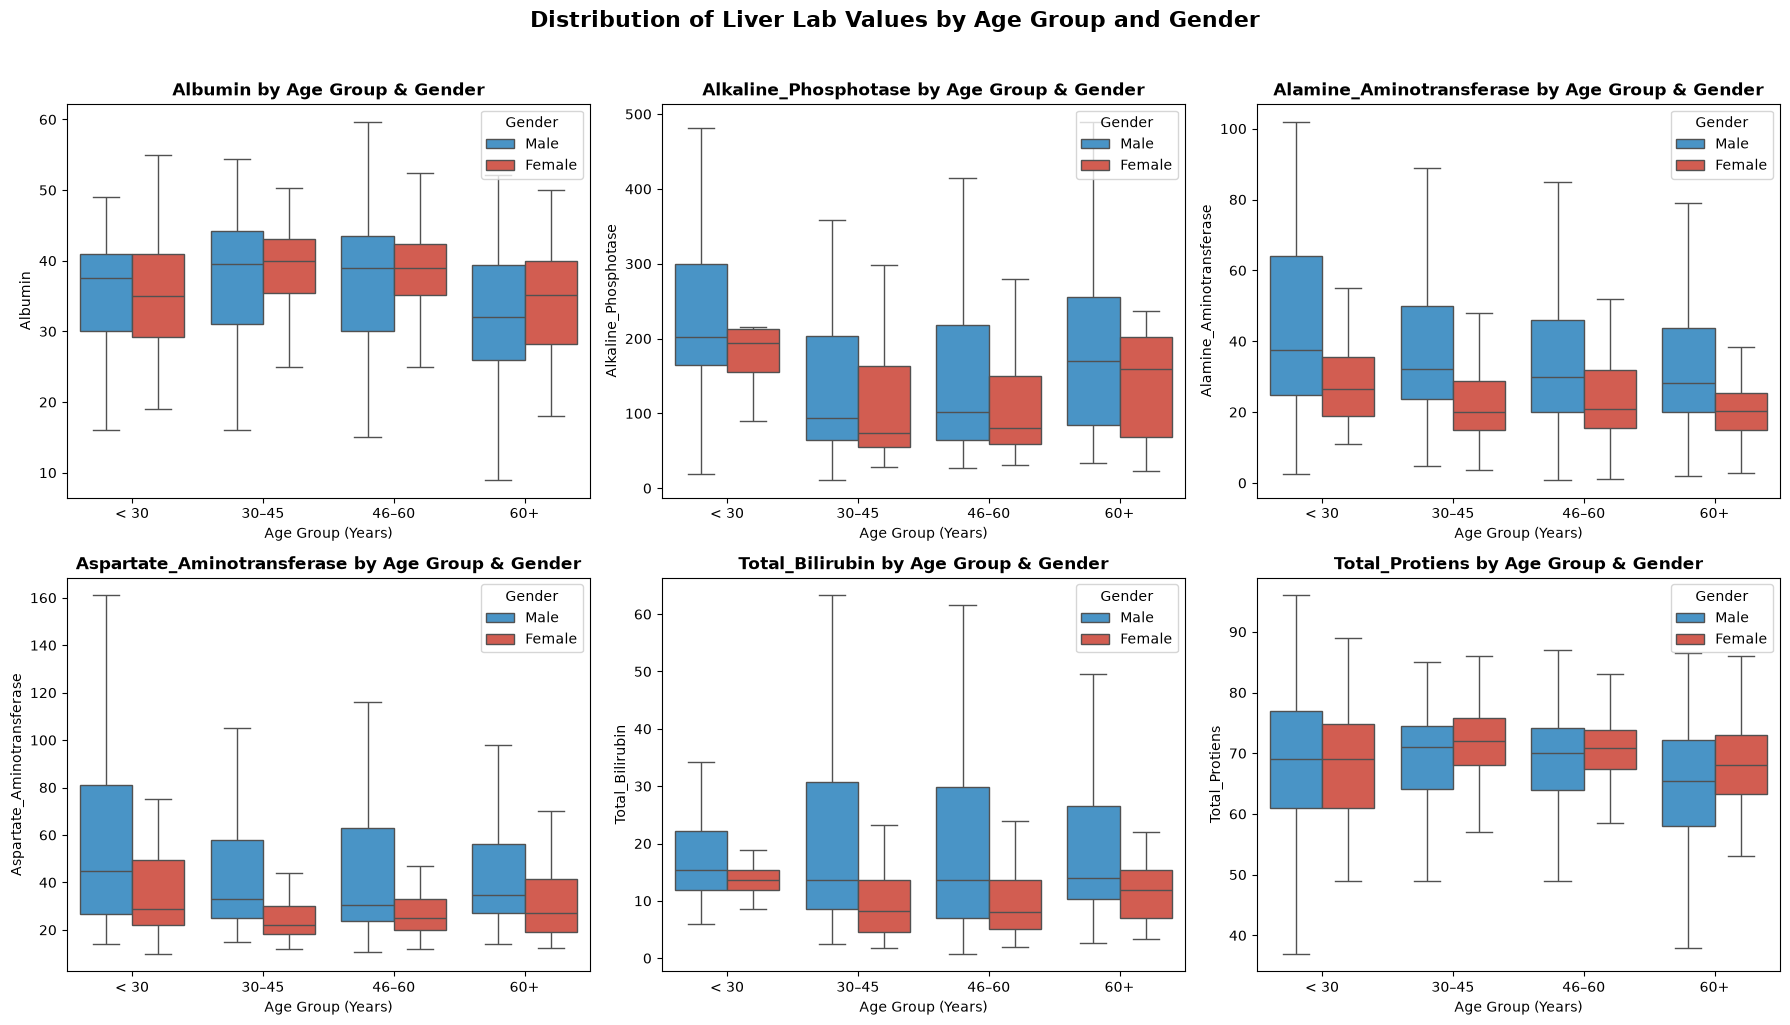

In [118]:
combined_datasets_cirrhosis['Gender'] = combined_datasets_cirrhosis['Gender'].replace({'m': 'Male', 'f': 'Female'})
bins = [0, 30, 45, 60, 120]
labels = ['< 30', '30–45', '46–60', '60+']
combined_datasets_cirrhosis['Age_Group'] = pd.cut(combined_datasets_cirrhosis['Age'], bins=bins, labels=labels)

markers = [
    'Albumin', 
    'Alkaline_Phosphotase', 
    'Alamine_Aminotransferase', 
    'Aspartate_Aminotransferase', 
    'Total_Bilirubin', 
    'Total_Protiens'
]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, marker in enumerate(markers):
    sns.boxplot(
        data=combined_datasets_cirrhosis,
        x='Age_Group',
        y=marker,
        hue='Gender',
        ax=axes[i],
        palette={'Male': '#3498db', 'Female': '#e74c3c'},
        showfliers=False
    )
    axes[i].set_title(f'{marker} by Age Group & Gender', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Age Group (Years)')
    axes[i].set_ylabel(marker)
    axes[i].legend(title='Gender', loc='upper right')

plt.suptitle('Distribution of Liver Lab Values by Age Group and Gender', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [119]:
print('Missing Values from the Dataset', combined_datasets_cirrhosis.isnull().sum())

Missing Values from the Dataset Dataset                        0
Age                            0
Gender                         0
Albumin                        1
Alkaline_Phosphotase          18
Alamine_Aminotransferase       1
Aspartate_Aminotransferase     0
Total_Bilirubin                0
Total_Protiens                 1
Source                         0
Age_Group                      0
dtype: int64


In [120]:
print("Missing Values from the Dataset", combined_datasets_cirrhosis.isna().sum())

Missing Values from the Dataset Dataset                        0
Age                            0
Gender                         0
Albumin                        1
Alkaline_Phosphotase          18
Alamine_Aminotransferase       1
Aspartate_Aminotransferase     0
Total_Bilirubin                0
Total_Protiens                 1
Source                         0
Age_Group                      0
dtype: int64


Separability - The process in which we can differentiate the health blood donors from patients with Hepatits C and Cirrhosis

In [121]:
cirrhosis_cleaned = combined_datasets_cirrhosis.dropna().copy()

In [122]:
markers = ['Albumin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase',
            'Aspartate_Aminotransferase', 'Total_Bilirubine', 'Total_Protiens']

In [123]:
healthy_data_set = cirrhosis_cleaned[cirrhosis_cleaned['Dataset'] == '0=Blood Donor']
cirrhosis_data_set = [cirrhosis_cleaned['Dataset'] == '3=Cirrhosis']
all_sick = cirrhosis_cleaned[cirrhosis_cleaned['Dataset'] !=  '0=Blood Donor']

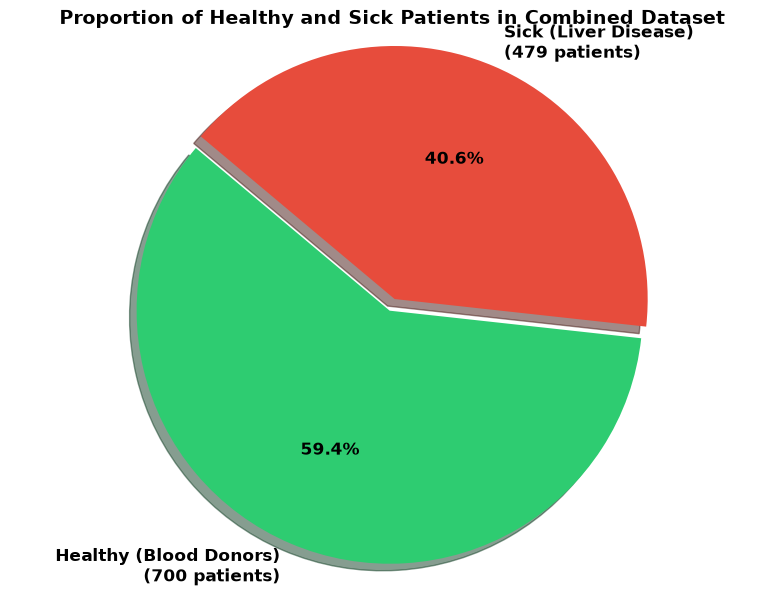

In [124]:
cirrhosis_cleaned['all_sick'] = (cirrhosis_cleaned['Dataset'] != '0=Blood Donor').astype(int)
counts = cirrhosis_cleaned['all_sick'].value_counts().sort_index()
labels = [
    f'Healthy (Blood Donors)\n({counts[0]} patients)', 
    f'Sick (Liver Disease)\n({counts[1]} patients)'
]
colors = ['#2ecc71', '#e74c3c']  
explode = (0, 0.05)
plt.figure(figsize=(8, 6))
plt.pie(
    counts, 
    labels=labels, 
    colors=colors, 
    explode=explode,
    autopct='%1.1f%%',
    startangle=140, 
    shadow=True,
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)

plt.title('Proportion of Healthy and Sick Patients in Combined Dataset', fontsize=14, fontweight='bold')
plt.axis('equal')
plt.tight_layout()
plt.show()

In [125]:
cirrhosis_cleaned['healthy_data_set'] = (cirrhosis_cleaned['Dataset'] == '0=Blood Donor').astype(int)
cirrhosis_cleaned['cirrhosis_data_set'] = (cirrhosis_cleaned['Dataset'] == '3=Cirrhosis').astype(int)
cirrhosis_cleaned['all_sick'] = (cirrhosis_cleaned['Dataset'] !=  '0=Blood Donor').astype(int)
display(cirrhosis_cleaned[['Dataset', 'healthy_data_set', 'cirrhosis_data_set',  'all_sick']])

,Dataset,healthy_data_set,cirrhosis_data_set,all_sick
0,0=Blood Donor,1,0,0
1,0=Blood Donor,1,0,0
2,0=Blood Donor,1,0,0
3,0=Blood Donor,1,0,0
4,0=Blood Donor,1,0,0
...,...,...,...,...
1193,0=Blood Donor,1,0,0
1194,Liver_Disease_General,0,0,1
1195,Liver_Disease_General,0,0,1
1196,Liver_Disease_General,0,0,1


In [126]:
display(cirrhosis_cleaned)

,Dataset,Age,Gender,Albumin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Bilirubin,Total_Protiens,Source,Age_Group,all_sick,healthy_data_set,cirrhosis_data_set
0,0=Blood Donor,32,Male,38.5,52.5,7.7,22.1,7.50,69.0,Hepatitis_Dataset,30–45,0,1,0
1,0=Blood Donor,32,Male,38.5,70.3,18.0,24.7,3.90,76.5,Hepatitis_Dataset,30–45,0,1,0
2,0=Blood Donor,32,Male,46.9,74.7,36.2,52.6,6.10,79.3,Hepatitis_Dataset,30–45,0,1,0
3,0=Blood Donor,32,Male,43.2,52.0,30.6,22.6,18.90,75.7,Hepatitis_Dataset,30–45,0,1,0
4,0=Blood Donor,32,Male,39.2,74.1,32.6,24.8,9.60,68.7,Hepatitis_Dataset,30–45,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1193,0=Blood Donor,60,Male,16.0,500.0,20.0,34.0,8.55,59.0,Indian_Dataset,46–60,0,1,0
1194,Liver_Disease_General,40,Male,32.0,98.0,35.0,31.0,10.26,60.0,Indian_Dataset,30–45,1,0,0
1195,Liver_Disease_General,52,Male,32.0,245.0,48.0,49.0,13.68,64.0,Indian_Dataset,46–60,1,0,0
1196,Liver_Disease_General,31,Male,34.0,184.0,29.0,32.0,22.23,68.0,Indian_Dataset,30–45,1,0,0


## 2. De Ritis Ratio ($\text{AST}/\text{ALT}$) Variability Analysis

In clinical hepatology, the **De Ritis Ratio** represents the ratio between Aspartate Aminotransferase ($\text{AST}$) and Alanine Aminotransferase ($\text{ALT}$):

$$\text{De Ritis Ratio} = \frac{\text{AST}}{\text{ALT}}$$

* **Healthy liver:** Typically $\approx 0.8 - 1.0$.
* **Acute viral hepatitis:** $\text{ALT}$ rises predominantly, pushing the ratio $< 1.0$.
* **Advanced fibrosis & Cirrhosis:** Mitochondrial damage releases more $\text{AST}$ while $\text{ALT}$ synthesis declines, elevating the ratio $> 1.5 - 2.0$.

Step 1 of Process : De Ritis Ratio ($\text{AST}/\text{ALT}$) Variability Analysis

Calculating of De Retiris Ratiso(by avoiding division by 0 using np.where function)


 De Ritis Ratio ($\text{AST}/\text{ALT}$)

In [127]:

cirrhosis_cleaned['De_Ritis_Ratio'] = np.where(
    cirrhosis_cleaned['Alamine_Aminotransferase'] > 0,
    cirrhosis_cleaned['Aspartate_Aminotransferase'] / cirrhosis_cleaned['Alamine_Aminotransferase'],
    np.nan
)



Calculationg Variability 


In [128]:
variability_summary_cirrhosis = cirrhosis_cleaned.groupby('Dataset')['De_Ritis_Ratio'].agg(
    Count='count',
    Mean='mean',
    Std='std',
    Median='median',
    Q25=lambda x: x.quantile(0.25),
    Q75=lambda x: x.quantile(0.75)
).round(2)

Diagram BoxPlot

C:\Users\dilya\AppData\Local\Temp\ipykernel_28016\1752486731.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


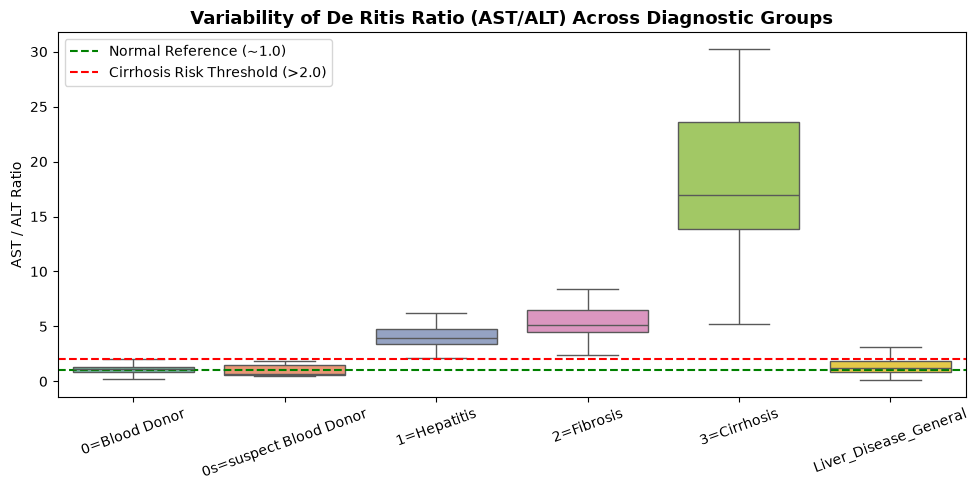

In [129]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=cirrhosis_cleaned, 
    x='Dataset', 
    y='De_Ritis_Ratio', 
    palette='Set2',
    showfliers=False
)
plt.axhline(1.0, color='green', linestyle='--', label='Normal Reference (~1.0)')
plt.axhline(2.0, color='red', linestyle='--', label='Cirrhosis Risk Threshold (>2.0)')
plt.title('Variability of De Ritis Ratio (AST/ALT) Across Diagnostic Groups', fontsize=13, fontweight='bold')
plt.ylabel('AST / ALT Ratio')
plt.xlabel('')
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

This visualization is a Boxplot (also called a box-and-whisker plot) showing how the De Ritis Ratio ($\text{AST} / \text{ALT}$) varies across different diagnostic groups in your combined dataset.


$\textcolor{purple}{\textbf{What Every Element in the Chart Means ?}}$

Horizontal Axis (X-axis — Diagnostic Groups): Shows the six patient categories from your combined files, progressing from healthy blood donors on the left (0=Blood Donor) to advanced liver damage (3=Cirrhosis) and general liver disease (Liver_Disease_General). 

(Note: 0s=suspect Blood Donor appears separately because it wasn't merged into 0=Blood Donor in the active dataframe).

Vertical Axis (Y-axis — AST / ALT Ratio): Measures the calculated value of $\text{AST} \div \text{ALT}$. 

Higher values indicate greater mitochondrial liver cell injury relative to standard cytoplasmic enzyme release.The Colored Boxes (Interquartile Range — IQR): Each colored box contains the middle 50% of patients in that group (from the 25th percentile at the bottom edge of the box to the 75th percentile at the top edge).

A taller box means higher variability among patients in that group.The Horizontal Line Inside Each Box (Median): Represents the exact middle value (50th percentile) of the group.
 
The "Whiskers" (Vertical T-lines above and below each box): Show the normal spread of the remaining data outside the middle 50% (excluding extreme outliers, which were hidden with showfliers=False).Green Dashed Line (Normal Reference ~1.0): Clinical baseline showing where healthy liver enzyme ratios typically sit.
 
Red Dashed Line (Cirrhosis Risk Threshold >2.0): Clinical threshold above which severe fibrosis or cirrhosis is strongly suspected.


Key Clinical & Statistical Takeaways from Your PlotHealthy Controls (0=Blood Donor & 0s=suspect Blood Donor):
 
Both boxes are tightly compressed right around the green dashed line (~1.0) with almost zero spread, confirming stable liver function.
Progressive Escalation (1=Hepatitis $\rightarrow$ 2=Fibrosis $\rightarrow$ 3=Cirrhosis): There is a clear upward staircase pattern.



As liver damage advances from Hepatitis (median ~4) to Fibrosis (median ~5), the ratio climbs steadily.Cirrhosis (3=Cirrhosis): Exhibits both the highest median (~17) and the widest variability (box spanning roughly from 14 to 24, with whiskers reaching 30), sitting far above the red risk threshold (>2.0).General Liver Disease (Liver_Disease_General):
 
This group from the secondary Indian dataset sits much lower (median ~1.3, straddling the green and red lines), because it mixes mild/early liver conditions with severe cases rather than isolating end-stage cirrhosis.


### $\color{purple}{\mathbf{Interpretation\ of\ De\ Ritis\ Ratio\ (AST/ALT)\ Variability}}$

The boxplot above illustrates the distribution and spread of the **De Ritis Ratio** across all diagnostic categories:

1. **Healthy Baseline (`0=Blood Donor`):** Healthy individuals exhibit a tightly clustered ratio right around the normal clinical reference of **~1.0** (green dashed line), with minimal variance.
2. **Disease Progression (`Hepatitis` $\rightarrow$ `Fibrosis` $\rightarrow$ `Cirrhosis`):** A clear upward trend is visible as liver pathology advances. While `1=Hepatitis` and `2=Fibrosis` show moderately elevated medians (~4.0 and ~5.0, respectively), **`3=Cirrhosis`** demonstrates a dramatic surge, reaching a **median of ~17.0** with a wide interquartile range (14.0–24.0), well above the clinical cirrhosis risk threshold of **2.0** (red dashed line).
3. **Cross-Dataset Comparison (`Liver_Disease_General`):** The general liver patient cohort from the secondary dataset displays a lower median (~1.3) than the confirmed cirrhosis group, reflecting a broader mix of early and moderate hepatobiliary conditions rather than exclusively end-stage cirrhosis.

**Conclusion:** The De Ritis Ratio provides strong visual and statistical separability between healthy donors and advanced cirrhosis cases, validating its utility as an engineered feature for predictive modeling.

### $\textcolor{purple}{\textbf{Statistical Hypothesis Testing and Correlation Analysis}}$

We evaluate the diagnostic power of liver biomarkers using formal statistical hypothesis testing at a significance level of $\alpha = 0.05$.

### 3.1 Formulating the Hypotheses

For each biochemical marker (`De_Ritis_Ratio`, `Albumin`, `Total_Bilirubin`, `Aspartate_Aminotransferase`, `Alamine_Aminotransferase`, `Alkaline_Phosphotase`, and `Total_Protiens`), we compare **Healthy Blood Donors** (`0=Blood Donor`) against **Confirmed Cirrhosis Patients** (`3=Cirrhosis`):

* **Null Hypothesis ($H_0$):** There is no statistically significant difference in the median biomarker levels between healthy blood donors and patients with cirrhosis ($\mu_{\text{healthy}} = \mu_{\text{cirrhosis}}$).
* **Alternative Hypothesis ($H_1$):** There is a statistically significant difference in biomarker levels between the two groups ($\mu_{\text{healthy}} \neq \mu_{\text{cirrhosis}}$).

### 3.2 Choice of Statistical Test
Because clinical lab values are heavily right-skewed and contain extreme outliers (violating the normality assumption of a standard parametric $t$-test / $z$-test), we apply the non-parametric **Mann–Whitney U test** (Wilcoxon rank-sum test) alongside a **Welch's $t$-test** for comparison. If $p\text{-value} < 0.05$, we reject $H_0$.

,Biomarker,Healthy_Median,Cirrhosis_Median,Change_in_Cirrhosis,MannWhitney_P_Value,Welch_T_P_Value,Statistical_Decision
0,De_Ritis_Ratio,1.10,16.98,Elevated ↑,8.77e-17,8.86e-06,Reject H0 (Significant)
1,Albumin,41.00,32.50,Decreased ↓,3.80e-09,1.91e-08,Reject H0 (Significant)
2,Total_Bilirubin,8.52,38.50,Elevated ↑,8.95e-11,8.36e-04,Reject H0 (Significant)
3,Aspartate_Aminotransferase,25.30,97.20,Elevated ↑,1.61e-12,3.62e-05,Reject H0 (Significant)
4,Alamine_Aminotransferase,24.00,4.95,Decreased ↓,6.94e-12,1.35e-12,Reject H0 (Significant)
5,Alkaline_Phosphotase,74.15,80.05,Elevated ↑,5.51e-01,5.07e-01,Fail to Reject H0
6,Total_Protiens,71.70,69.50,Decreased ↓,2.10e-01,3.96e-01,Fail to Reject H0


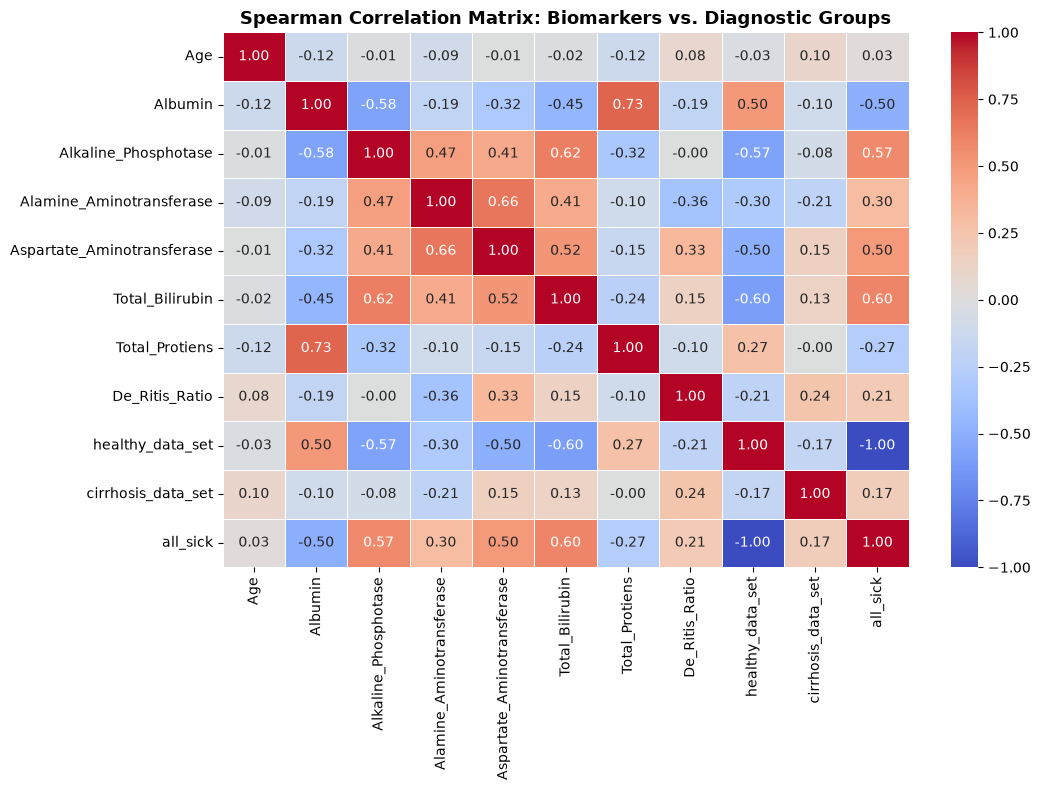

,Group,Total_Patients,High_De_Ritis (> 2.0) %,Low_Albumin (< 35 g/L) %,Elevated_Bilirubin (> 21 µmol/L) %
0,Healthy (0=Blood Donor),700,3.9,15.7,8.0
1,Confirmed Cirrhosis (3=Cirrhosis),24,100.0,70.8,66.7


In [130]:
healthy = cirrhosis_cleaned[cirrhosis_cleaned['Dataset'] == '0=Blood Donor']
cirrhosis_group = cirrhosis_cleaned[cirrhosis_cleaned['Dataset'] == '3=Cirrhosis']

test_markers = [
    'De_Ritis_Ratio',
    'Albumin',
    'Total_Bilirubin',
    'Aspartate_Aminotransferase',
    'Alamine_Aminotransferase',
    'Alkaline_Phosphotase',
    'Total_Protiens'
]

hypothesis_results = []

for col in test_markers:
    h_vals = healthy[col].dropna()
    c_vals = cirrhosis_group[col].dropna()
    
    u_stat, p_val_mw = stats.mannwhitneyu(h_vals, c_vals, alternative='two-sided')
    
    t_stat, p_val_t = stats.ttest_ind(h_vals, c_vals, equal_var=False)
    
    direction = 'Elevated ↑' if c_vals.median() > h_vals.median() else 'Decreased ↓'
    decision = 'Reject H0 (Significant)' if p_val_mw < 0.05 else 'Fail to Reject H0'
    
    hypothesis_results.append({
        'Biomarker': col,
        'Healthy_Median': round(h_vals.median(), 2),
        'Cirrhosis_Median': round(c_vals.median(), 2),
        'Change_in_Cirrhosis': direction,
        'MannWhitney_P_Value': f"{p_val_mw:.2e}",
        'Welch_T_P_Value': f"{p_val_t:.2e}",
        'Statistical_Decision': decision
    })

results_df = pd.DataFrame(hypothesis_results)
display(results_df)
import matplotlib.pyplot as plt

corr_cols = [
    'Age', 'Albumin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase',
    'Aspartate_Aminotransferase', 'Total_Bilirubin', 'Total_Protiens',
    'De_Ritis_Ratio', 'healthy_data_set', 'cirrhosis_data_set', 'all_sick'
]

plt.figure(figsize=(11, 8))
corr_matrix = cirrhosis_cleaned[corr_cols].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Spearman Correlation Matrix: Biomarkers vs. Diagnostic Groups', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

risk_summary = pd.DataFrame({
    'Group': ['Healthy (0=Blood Donor)', 'Confirmed Cirrhosis (3=Cirrhosis)'],
    'Total_Patients': [len(healthy), len(cirrhosis_group)],
    'High_De_Ritis (> 2.0) %': [
        round((healthy['De_Ritis_Ratio'] > 2.0).mean() * 100, 1),
        round((cirrhosis_group['De_Ritis_Ratio'] > 2.0).mean() * 100, 1)
    ],
    'Low_Albumin (< 35 g/L) %': [
        round((healthy['Albumin'] < 35.0).mean() * 100, 1),
        round((cirrhosis_group['Albumin'] < 35.0).mean() * 100, 1)
    ],
    'Elevated_Bilirubin (> 21 µmol/L) %': [
        round((healthy['Total_Bilirubin'] > 21.0).mean() * 100, 1),
        round((cirrhosis_group['Total_Bilirubin'] > 21.0).mean() * 100, 1)
    ]
})

display(risk_summary)

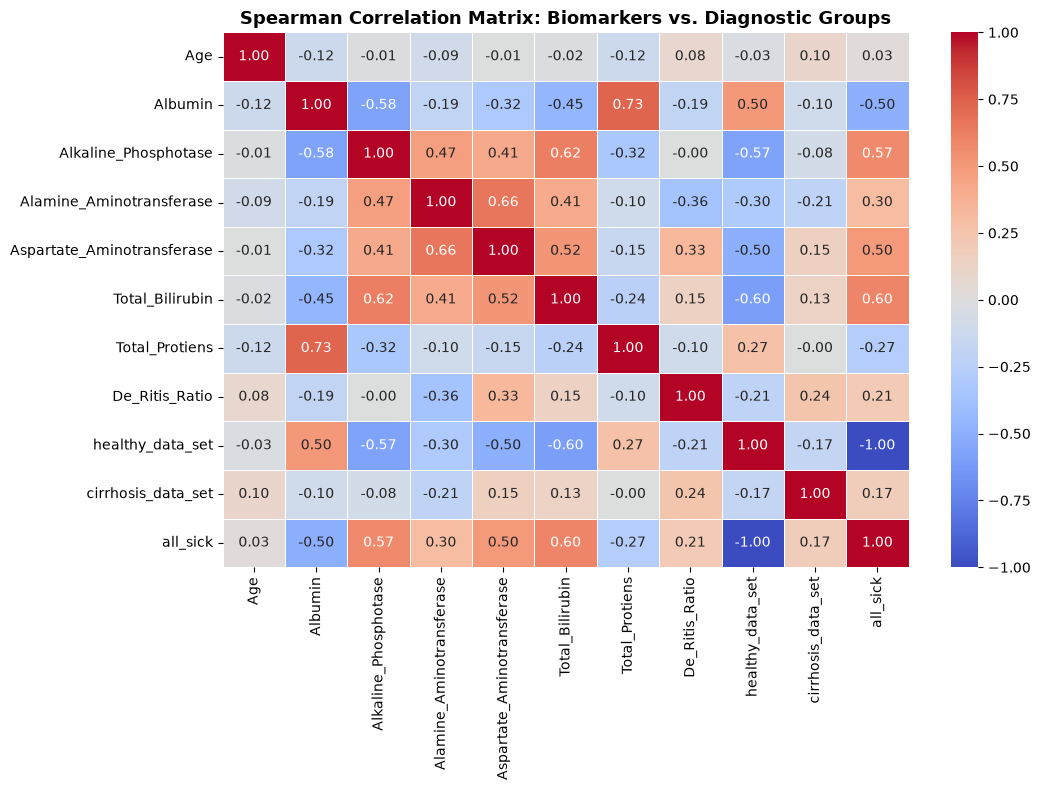

,Group,Total_Patients,High_De_Ritis (> 2.0) %,Low_Albumin (< 35 g/L) %,Elevated_Bilirubin (> 21 µmol/L) %
0,Healthy (0=Blood Donor),700,3.9,15.7,8.0
1,Confirmed Cirrhosis (3=Cirrhosis),24,100.0,70.8,66.7


In [131]:
corr_cols = [
    'Age', 'Albumin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase',
    'Aspartate_Aminotransferase', 'Total_Bilirubin', 'Total_Protiens',
    'De_Ritis_Ratio', 'healthy_data_set', 'cirrhosis_data_set', 'all_sick'
]

plt.figure(figsize=(11, 8))
corr_matrix = cirrhosis_cleaned[corr_cols].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Spearman Correlation Matrix: Biomarkers vs. Diagnostic Groups', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

risk_summary = pd.DataFrame({
    'Group': ['Healthy (0=Blood Donor)', 'Confirmed Cirrhosis (3=Cirrhosis)'],
    'Total_Patients': [len(healthy), len(cirrhosis_group)],
    'High_De_Ritis (> 2.0) %': [
        round((healthy['De_Ritis_Ratio'] > 2.0).mean() * 100, 1),
        round((cirrhosis_group['De_Ritis_Ratio'] > 2.0).mean() * 100, 1)
    ],
    'Low_Albumin (< 35 g/L) %': [
        round((healthy['Albumin'] < 35.0).mean() * 100, 1),
        round((cirrhosis_group['Albumin'] < 35.0).mean() * 100, 1)
    ],
    'Elevated_Bilirubin (> 21 µmol/L) %': [
        round((healthy['Total_Bilirubin'] > 21.0).mean() * 100, 1),
        round((cirrhosis_group['Total_Bilirubin'] > 21.0).mean() * 100, 1)
    ]
})

display(risk_summary)